In [1]:
#import some basic classes
import numpy as np
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.util as cutil
import matplotlib.pyplot as plt
import statsmodels.api as sm
from tqdm import tqdm
from scipy import stats
#my own classes
import sys
sys.path.append("/Users/michelefilippucci/Prog/github/blocktrack/lib")
import blocktoolbox as BT
sys.path.append("/Users/michelefilippucci/Prog/github/AtmBlockPy/lib")
import BlockPlots as BP

In [2]:
%cd /Users/michelefilippucci/Data/ERA5/gr_tracking
!ls

/Users/michelefilippucci/Data/ERA5/gr_tracking
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1990.nc
dictionaries


In [3]:
ds_filt = xr.open_dataset('ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc')
ds_unfilt = xr.open_dataset('ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023.nc')

In [4]:
#Greenland coordinates
plon,plat=-35.0,70.0 #Greenland

In [5]:
DAV_filt = ds_filt['DAV_tracked']
DAV_unfilt = ds_unfilt['DAV_tracked']
zg = ds_filt['zg']

In [6]:
times = ds_filt['time']
lons = ds_filt['lon']
lats = ds_filt['lat']

In [7]:
def running_mean(data,window):
    new_data = []
    for i in range(len(data)-window):
        new_data.append(np.sum(data[i:i+window])/window)
    print(len(new_data))
    return new_data

In [8]:
count = 0
count_m = 0
months = ['06','07','08']
DAV_series = DAV_filt.loc[:,plat,plon]
freq_per_year = []
tmp = 0
for t,time in tqdm(enumerate(times)):
    month = str(time.values)[5:7]
    time_diff = t-tmp
    if month in months:
        count_m +=1
        if DAV_series[t] > 0:
            count += 1
    if time_diff == 365:
        tmp = t
        freq_per_year.append(count/count_m)
        count = 0
        count_m = 0

30681it [00:05, 5491.38it/s]


In [9]:
def fit_with_bootstrap(freq_per_year,years,N_it):
    pends = []
    count = 0
    for i in range(N_it):
        tmp = np.random.choice(freq_per_year, size=len(freq_per_year),replace=False)
        coefficients = np.polyfit(years, tmp, 1)
        pend = coefficients[0]
        pends.append(pend)
    coefficients = np.polyfit(years, freq_per_year, 1)
    pend_exp = coefficients[0]
    for pend in pends:
        if abs(pend) > abs(pend_exp):
            count += 1
    p_value = count/N_it
    return pend_exp,p_value

74
0.0007500957428545054 0.0005


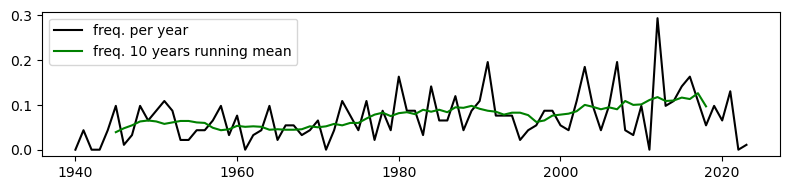

In [10]:
window = 10
freq_per_year_run_avg = running_mean(freq_per_year,window)
years = np.arange(1940,2024,1)
years_run_avg = years[int(window/2):int(-window/2)]


# Fit linear regression model with errors
pend,p_value = fit_with_bootstrap(freq_per_year,years,2000)

print(pend,p_value)

plt.rcParams['figure.figsize'] = [8,2]
plt.plot(years,freq_per_year,color='black',label='freq. per year')
plt.plot(years_run_avg,freq_per_year_run_avg,color='g',label='freq. 10 years running mean')
plt.legend()
plt.tight_layout()
plt.savefig('/Users/michelefilippucci/PLOTS/EGU/frequency_ERA5',dpi=300)

In [11]:
print(pend,p_value)

0.0007500957428545054 0.0005


In [13]:
DAV_bool = DAV_filt
ds = ds_filt
dic_for_filtering = np.load('dictionaries/ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023_DIC.npy',allow_pickle=True) #original
#create a list of indexes
indexes = []
timings = []
for t in tqdm(range(len(ds["time"].values))):
    for l in np.unique(DAV_bool[t,:,:]):
        #if l < 4907: #i need to fix this but couriously it's working
        month = str(dic_for_filtering[l-1]['date'])[5:7]
        if l!=0 and np.all(l==DAV_bool[t:t+1,:,:].loc[:,plat,plon]) and month in months and not l in indexes: #and dic_for_filtering[l-1]['distance_traveled']>1500#DAV_bool[t-1,:,:]:
            indexes.append(l)
            timings.append(t)
print(len(indexes))

100%|████████████████████████████████████████████████████████████████| 30681/30681 [00:44<00:00, 695.42it/s]

153


In [14]:
print(len(dic_for_filtering))

5568


In [15]:
print(np.amax(DAV_bool))

<xarray.DataArray 'DAV_tracked' ()>
array(5568)


In [16]:
"""
A list of trajectories is then produced
"""
dic = []
for i,l in tqdm(enumerate(indexes)):
    dic.append({})
    dic[i]['track'] = dic_for_filtering[l-1]['track']
    dic[i]['area'] = dic_for_filtering[l-1]['avg_area']
    dic[i]['date'] = dic_for_filtering[l-1]['date']
    dic[i]['avg_dist_traveled'] = dic_for_filtering[l-1]['avg_dist_traveled']

153it [00:00, 445954.49it/s]


/Users/michelefilippucci/miniconda3/envs/blocktoolbox_env/lib/python3.11/site-packages/cartopy/mpl/gridliner.py:451: UserWarning: The .xlabels_top attribute is deprecated. Please use .top_labels to toggle visibility instead.
  warnings.warn('The .xlabels_top attribute is deprecated. Please '
/Users/michelefilippucci/miniconda3/envs/blocktoolbox_env/lib/python3.11/site-packages/cartopy/mpl/gridliner.py:475: UserWarning: The .ylabels_left attribute is deprecated. Please use .left_labels to toggle visibility instead.
  warnings.warn('The .ylabels_left attribute is deprecated. Please '


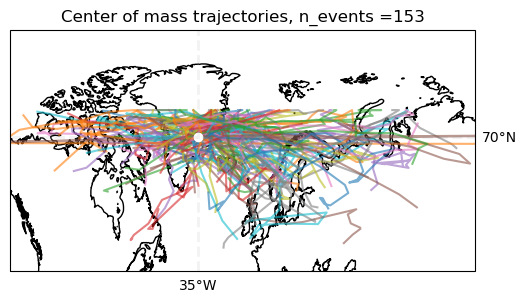

In [17]:
'''
TRAJECTORY PLOT
'''

import matplotlib.ticker as mticker

plt.figure(figsize=(6,6))

#dic =np.load("/Users/michelefilippucci/Prog/summer_greenland_block/data_tmp/dic_"+str(plon)+"-"+str(plat)+".npy",allow_pickle=True)
xs=[]
ys=[]
areas = []
for i in range(len(indexes)):
    #if 1959 == int(str(ds["time"].values[timings[i]])[0:4]):
    xs.append(dic[i]['track'][0])
    ys.append(dic[i]['track'][1])
    areas.append(dic[i]['area'])
output = "/home/mich/plots/POSTER/snapshots/trajectories_"+str(plon)+"-"+str(plat)+".png"
#plot the trajectories to see what you are looking at
mapcrs = ccrs.PlateCarree()
datacrs = ccrs.PlateCarree()
extent =[-140,+120,45,90]
ax = plt.subplot(111, projection=mapcrs)
ax.set_extent(extent, datacrs)
ax.coastlines()
ax.set_aspect(3)
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                linewidth=2, color='gray', alpha=0.1, linestyle='--')
gl.xlocator = mticker.FixedLocator([plon])
gl.ylocator = mticker.FixedLocator([plat])
gl.xlabels_top = False
gl.ylabels_left = False
for i in range(len(xs)):
    cm = plt.plot(ys[i],xs[i],alpha=0.6,transform=datacrs)
#plt.text(30,60, 'n_events='+str(len(xs)), fontsize = 9)
plt.plot(plon,plat,'ow',transform=datacrs)#transorm=datacrs)
plt.title('Center of mass trajectories, n_events =' + str(len(xs)), loc = 'center')


#plt.show()
#plt.savefig(output,bbox_inches='tight',dpi=400)
plt.savefig('/Users/michelefilippucci/PLOTS/EGU/trajectories.png',dpi=300)


In [18]:
xs=[]
ys=[]
areas = []
for i in range(len(indexes)):
    xs.append(dic[i]['track'][1])
    ys.append(dic[i]['track'][0])
    areas.append(dic[i]['area'])
#we want to store:
#-event label: dictionary key*
#-month
#-year
#-avg area in lifetime
#-initial distance from point
#-final distance from point 
#-duration
feature_dictionaries = []
for i,l in tqdm(enumerate(indexes)):
    event = {"label":l,
            "month":str(ds["time"].values[timings[i]])[5:7],
            "year":str(ds["time"].values[timings[i]])[0:4],
            "avg_area":np.mean(areas[i]),
            "duration":len(xs[i]),
            "initial_distance":((plon-xs[i][0])**2+(plat-ys[i][0])**2)**0.5,
            "final_distance":((plon-xs[i][-1])**2+(plat-ys[i][-1])**2)**0.5,
            "displacement_lon":plon-xs[i][0],
            "displacement_lat":plat-ys[i][0]
            }
    feature_dictionaries.append(event)

153it [00:00, 38078.00it/s]


In [19]:
def feature_list(feature_dictionaries,quantity,bin_size_y=10,year_range=(1943,2024)):
    y_array = np.arange(year_range[0]+bin_size_y/2,year_range[1]-bin_size_y/2,1)
    arr = np.zeros(len(y_array))
    arr_err = np.zeros(len(y_array))
    list_err = []
    for j,y in enumerate(y_array):
        count = 0
        for item in feature_dictionaries:
            if int(item["year"]) >= y-bin_size_y/2 and int(item["year"]) < y + bin_size_y/2:
                count += 1
                try:
                    arr[j] += item[quantity]
                    list_err.append(item[quantity])
                except:
                    arr[j] += 1 #the number of events case
        if quantity != "number_of_events":
            arr[j] = arr[j]/count
    if quantity != "number_of_events":
        for j,y in enumerate(y_array):
            arr_err[j] = np.std(list_err)
    if quantity == "number_of_events":
        for j,y in enumerate(y_array):
            arr_err[j]=np.std(arr[:])
    return y_array,arr,arr_err

-897.3900735118955 0.2005
0.08735747820254838 0.0
0.015172892443841462 0.0075


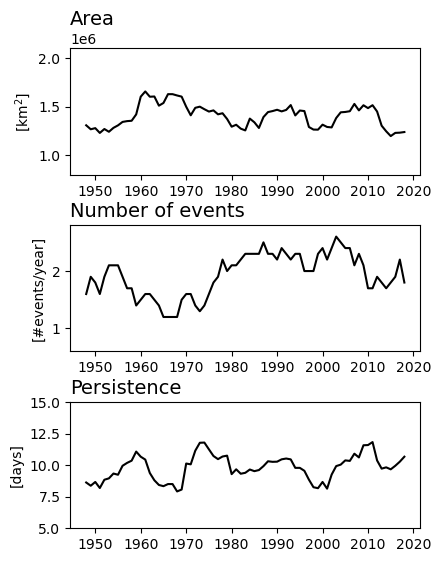

In [20]:
y,area,area_err = feature_list(feature_dictionaries,'avg_area')
y,n_ev,n_ev_err = feature_list(feature_dictionaries,'number_of_events')
y,duration,duration_err = feature_list(feature_dictionaries,'duration')
# Fit linear regression model with errors

pend,p_value = fit_with_bootstrap(area,y,2000)
print(pend,p_value)
pend,p_value = fit_with_bootstrap(n_ev,y,2000)
print(pend,p_value)
pend,p_value = fit_with_bootstrap(duration,y,2000)
print(pend,p_value)

plt.rcParams['figure.figsize'] = [5,6]

fig, axes = plt.subplots(nrows=3,ncols=1)
axes.flatten()
axes[0].plot(y,area,color='black',label='area')
axes[0].set_title('Area',loc='left',fontsize=14)
axes[0].set_ylabel('[km$^2$]')
axes[0].set_ylim((0.8e6,2.1e6))
axes[1].plot(y,n_ev/10,color='black',label='number_of_events')
axes[1].set_title('Number of events',loc='left',fontsize=14)
axes[1].set_ylabel('[#events/year]')
axes[1].set_ylim((0.6,2.8))
axes[2].plot(y,duration,color='black',label='persistence')
axes[2].set_title('Persistence',loc='left',fontsize=14)
axes[2].set_ylabel('[days]')
axes[2].set_ylim((5,15))

plt.subplots_adjust(left=0.2,
                    bottom=0.1, 
                    right=0.9, 
                    top=0.9, 
                    wspace=0.4, 
                    hspace=0.4)


plt.savefig('/Users/michelefilippucci/PLOTS/EGU/characteristics.png',dpi=300)

In [21]:
# LET'S TRY TO SELECT EVENTS COMING FROM THE WEST AND EAST
feature_dictionaries_east = []
feature_dictionaries_west = []
for i,l in tqdm(enumerate(indexes)):
    displacement_lon = plon-xs[i][0]
    if displacement_lon < 0:
        event = {"label":l,
                "month":str(ds["time"].values[timings[i]])[5:7],
                "year":str(ds["time"].values[timings[i]])[0:4],
                "avg_area":np.mean(areas[i]),
                "duration":len(xs[i]),
                "initial_distance":((plon-xs[i][0])**2+(plat-ys[i][0])**2)**0.5,
                "final_distance":((plon-xs[i][-1])**2+(plat-ys[i][-1])**2)**0.5,
                "displacement_lon":plon-xs[i][0],
                "displacement_lat":plat-ys[i][0]
                }
        feature_dictionaries_east.append(event)
    if displacement_lon >= 0:
        event = {"label":l,
                "month":str(ds["time"].values[timings[i]])[5:7],
                "year":str(ds["time"].values[timings[i]])[0:4],
                "avg_area":np.mean(areas[i]),
                "duration":len(xs[i]),
                "initial_distance":((plon-xs[i][0])**2+(plat-ys[i][0])**2)**0.5,
                "final_distance":((plon-xs[i][-1])**2+(plat-ys[i][-1])**2)**0.5,
                "displacement_lon":plon-xs[i][0],
                "displacement_lat":plat-ys[i][0]
                }
        feature_dictionaries_west.append(event)

153it [00:00, 40000.53it/s]


-1753.9835152406597 0.1295
0.07320590207914131 0.0
0.008965904973346978 0.2225
88


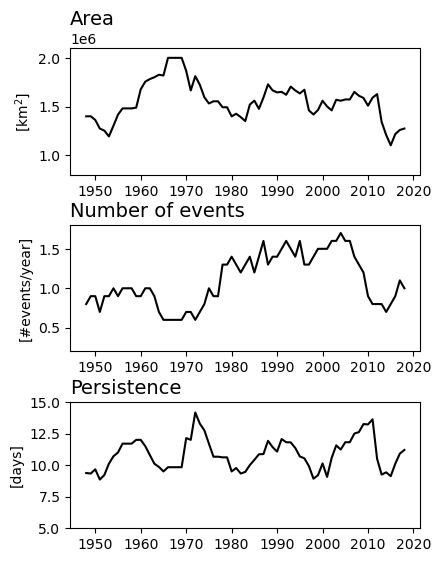

In [22]:
#EAST

y,area,area_err = feature_list(feature_dictionaries_east,'avg_area')
y,n_ev,n_ev_err = feature_list(feature_dictionaries_east,'number_of_events')
y,duration,duration_err = feature_list(feature_dictionaries_east,'duration')
# Fit linear regression model with errors

pend,p_value = fit_with_bootstrap(area,y,2000)
print(pend,p_value)
pend,p_value = fit_with_bootstrap(n_ev,y,2000)
print(pend,p_value)
pend,p_value = fit_with_bootstrap(duration,y,2000)
print(pend,p_value)
print(len(feature_dictionaries_east))

fig, axes = plt.subplots(nrows=3,ncols=1)
axes.flatten()
axes[0].plot(y,area,color='black',label='area')
axes[0].set_title('Area',loc='left',fontsize=14)
axes[0].set_ylabel('[km$^2$]')
axes[0].set_ylim((0.8e6,2.1e6))
axes[1].plot(y,n_ev/10,color='black',label='number_of_events')
axes[1].set_title('Number of events',loc='left',fontsize=14)
axes[1].set_ylabel('[#events/year]')
axes[1].set_ylim((0.2,1.8))
axes[2].plot(y,duration,color='black',label='persistence')
axes[2].set_title('Persistence',loc='left',fontsize=14)
axes[2].set_ylabel('[days]')
axes[2].set_ylim((5,15))

plt.subplots_adjust(left=0.2,
                    bottom=0.1, 
                    right=0.9, 
                    top=0.9, 
                    wspace=0.4, 
                    hspace=0.4)

plt.savefig('/Users/michelefilippucci/PLOTS/EGU/characteristics_from_east.png',dpi=300)


-1396.5021548623831 0.089
0.014151576123407087 0.1485
0.010635705769005573 0.156
65


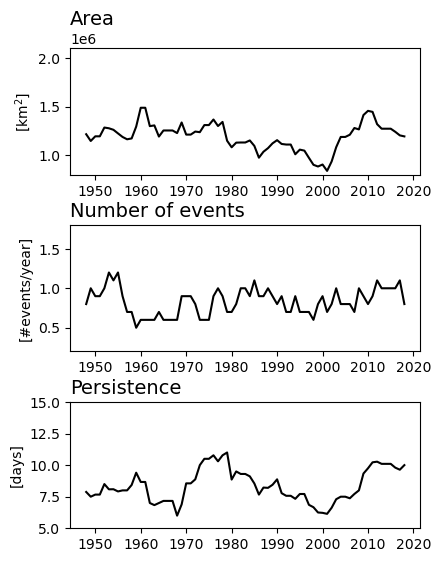

In [23]:
#WEST

y,area,area_err = feature_list(feature_dictionaries_west,'avg_area')
y,n_ev,n_ev_err = feature_list(feature_dictionaries_west,'number_of_events')
y,duration,duration_err = feature_list(feature_dictionaries_west,'duration')
# Fit linear regression model with errors

pend,p_value = fit_with_bootstrap(area,y,2000)
print(pend,p_value)
pend,p_value = fit_with_bootstrap(n_ev,y,2000)
print(pend,p_value)
pend,p_value = fit_with_bootstrap(duration,y,2000)
print(pend,p_value)
print(len(feature_dictionaries_west))

fig, axes = plt.subplots(nrows=3,ncols=1)
axes.flatten()
axes[0].plot(y,area,color='black',label='area')
axes[0].set_title('Area',loc='left',fontsize=14)
axes[0].set_ylabel('[km$^2$]')
axes[0].set_ylim((0.8e6,2.1e6))
axes[1].plot(y,n_ev/10,color='black',label='number_of_events')
axes[1].set_title('Number of events',loc='left',fontsize=14)
axes[1].set_ylabel('[#events/year]')
axes[1].set_ylim((0.2,1.8))
axes[2].plot(y,duration,color='black',label='persistence')
axes[2].set_title('Persistence',loc='left',fontsize=14)
axes[2].set_ylabel('[days]')
axes[2].set_ylim((5,15))

plt.subplots_adjust(left=0.2,
                    bottom=0.1, 
                    right=0.9, 
                    top=0.9, 
                    wspace=0.4, 
                    hspace=0.4)

plt.savefig('/Users/michelefilippucci/PLOTS/EGU/characteristics_from_west.png',dpi=300)

In [24]:
#COMPOSITES EAST WEST

In [25]:
labels_est = []
for event in feature_dictionaries_east:
    labels_est.append(event['label'])
labels_west = []
for event in feature_dictionaries_west:
    labels_west.append(event['label'])

In [ ]:
print(labels_est)
print(labels_west)